<a href="https://colab.research.google.com/github/Elianap123/CLV-Prediction-Online-Retail/blob/main/Copy_of_Untitled2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import files
uploaded = files.upload()

Saving Copy of online_retail_II (version 1).xlsx to Copy of online_retail_II (version 1).xlsx


In [ ]:
!pip install lifetimes xgboost lightgbm shap --quiet

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 584.2/584.2 kB 9.8 MB/s eta 0:00:00


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.model_selection import train_test_split, TimeSeriesSplit, cross_val_score
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from scipy.stats import spearmanr
import xgboost as xgb
import lightgbm as lgb
import warnings
warnings.filterwarnings('ignore')

print('Imports OK')

Imports OK


In [ ]:
FILE = 'Copy of online_retail_II (version 1).xlsx'

print('Φορτώνω το Excel... (1-2 λεπτά)')
df1 = pd.read_excel(FILE, sheet_name='Year 2009-2010')
df2 = pd.read_excel(FILE, sheet_name='Year 2010-2011')
df_raw = pd.concat([df1, df2], ignore_index=True)

# Καθαρισμός
df = df_raw[['Invoice','StockCode','Description','Quantity',
             'InvoiceDate','Price','Customer ID','Country']].copy()
df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'])
df['Revenue'] = df['Quantity'] * df['Price']
df = df[~df['Invoice'].astype(str).str.startswith('C')]
df = df.dropna(subset=['Customer ID'])
df = df[df['Quantity'] > 0]
df = df[df['Price'] > 0]
df['Customer ID'] = df['Customer ID'].astype(int)

# Temporal split
cutoff_date = pd.Timestamp('2011-06-01')
df_feat = df[df['InvoiceDate'] < cutoff_date].copy()
df_targ = df[df['InvoiceDate'] >= cutoff_date].copy()

# RFM
snapshot_date = df_feat['InvoiceDate'].max() + pd.Timedelta(days=1)
rfm = df_feat.groupby('Customer ID').agg(
    Recency   = ('InvoiceDate', lambda x: (snapshot_date - x.max()).days),
    Frequency = ('Invoice',     'nunique'),
    Monetary  = ('Revenue',     'sum')
).reset_index()

# Future CLV
future_clv = df_targ.groupby('Customer ID')['Revenue'].sum().reset_index()
future_clv.columns = ['Customer ID', 'Future_CLV']
df_model = rfm.merge(future_clv, on='Customer ID', how='left')
df_model['Future_CLV'] = df_model['Future_CLV'].fillna(0)

# Log transform
df_model['Monetary_log']   = np.log1p(df_model['Monetary'])
df_model['Future_CLV_log'] = np.log1p(df_model['Future_CLV'])

# Αποθήκευση στο Drive
df_model.to_csv('/content/drive/MyDrive/clv_dataset_ready.csv', index=False)
df.to_csv('/content/drive/MyDrive/df_clean.csv', index=False)

print(f'✅ Έτοιμο! Πελάτες: {len(df_model):,}')
print(f'Future CLV > 0: {(df_model["Future_CLV"] > 0).sum():,}')

Φορτώνω το Excel... (1-2 λεπτά)


OSError: Cannot save file into a non-existent directory: '/content/drive/MyDrive'

In [ ]:
df_model.to_csv('clv_dataset_ready.csv', index=False)
df.to_csv('df_clean.csv', index=False)

print(f'✅ Έτοιμο! Πελάτες: {len(df_model):,}')
print(f'Future CLV > 0: {(df_model["Future_CLV"] > 0).sum():,}')

✅ Έτοιμο! Πελάτες: 4,933
Future CLV > 0: 2,602


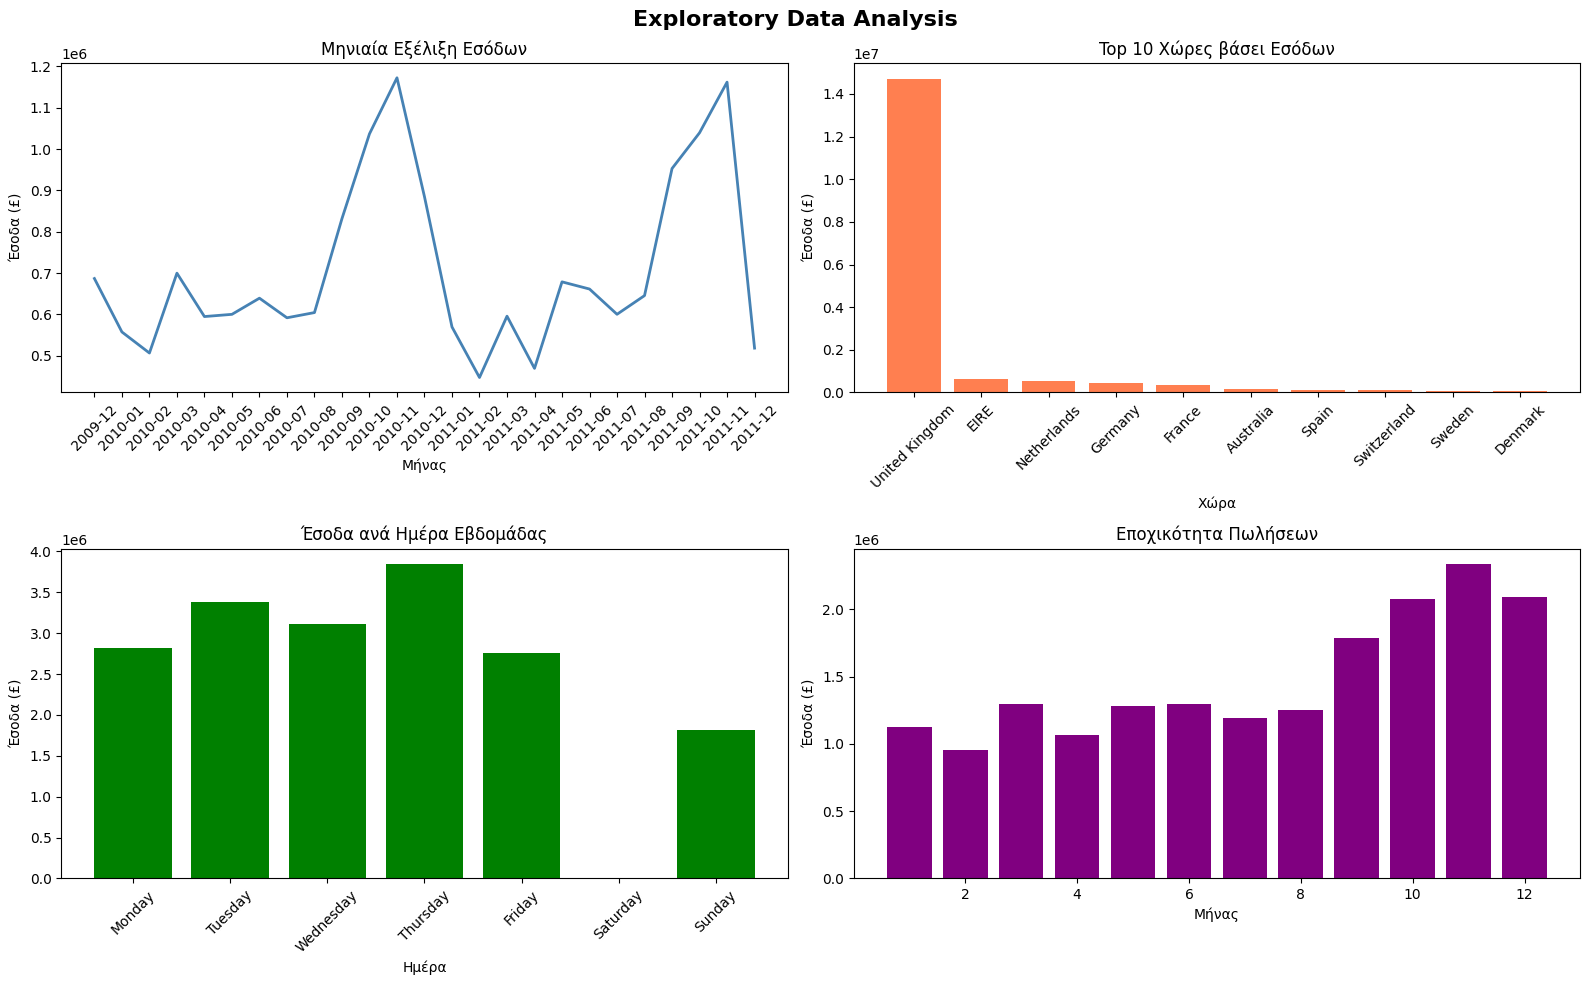

✅ EDA OK


In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(16, 10))
fig.suptitle('Exploratory Data Analysis', fontsize=16, fontweight='bold')

# 1. Μηνιαία εξέλιξη εσόδων
df['YearMonth'] = df['InvoiceDate'].dt.to_period('M')
monthly = df.groupby('YearMonth')['Revenue'].sum()
axes[0,0].plot(monthly.index.astype(str), monthly.values, color='steelblue', linewidth=2)
axes[0,0].set_title('Μηνιαία Εξέλιξη Εσόδων')
axes[0,0].set_xlabel('Μήνας')
axes[0,0].set_ylabel('Έσοδα (£)')
axes[0,0].tick_params(axis='x', rotation=45)

# 2. Top 10 χώρες
country = df.groupby('Country')['Revenue'].sum().sort_values(ascending=False).head(10)
axes[0,1].bar(country.index, country.values, color='coral')
axes[0,1].set_title('Top 10 Χώρες βάσει Εσόδων')
axes[0,1].set_xlabel('Χώρα')
axes[0,1].set_ylabel('Έσοδα (£)')
axes[0,1].tick_params(axis='x', rotation=45)

# 3. Έσοδα ανά ημέρα εβδομάδας
df['DayOfWeek'] = df['InvoiceDate'].dt.day_name()
order = ['Monday','Tuesday','Wednesday','Thursday','Friday','Saturday','Sunday']
weekly = df.groupby('DayOfWeek')['Revenue'].sum().reindex(order)
axes[1,0].bar(weekly.index, weekly.values, color='green')
axes[1,0].set_title('Έσοδα ανά Ημέρα Εβδομάδας')
axes[1,0].set_xlabel('Ημέρα')
axes[1,0].set_ylabel('Έσοδα (£)')
axes[1,0].tick_params(axis='x', rotation=45)

# 4. Εποχικότητα (ανά μήνα)
df['Month'] = df['InvoiceDate'].dt.month
seasonal = df.groupby('Month')['Revenue'].sum()
axes[1,1].bar(seasonal.index, seasonal.values, color='purple')
axes[1,1].set_title('Εποχικότητα Πωλήσεων')
axes[1,1].set_xlabel('Μήνας')
axes[1,1].set_ylabel('Έσοδα (£)')

plt.tight_layout()
plt.savefig('EDA_plots.png', dpi=150, bbox_inches='tight')
plt.show()
print('✅ EDA OK')

In [ ]:
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.mixture import GaussianMixture
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score, calinski_harabasz_score, davies_bouldin_score

# Standardization
scaler = StandardScaler()
rfm_data = df_model[['Recency','Frequency','Monetary']].copy()
rfm_scaled = scaler.fit_transform(rfm_data)

# K-Means
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
df_model['Cluster_KM'] = kmeans.fit_predict(rfm_scaled)
km_sil = silhouette_score(rfm_scaled, df_model['Cluster_KM'])
km_ch  = calinski_harabasz_score(rfm_scaled, df_model['Cluster_KM'])
km_db  = davies_bouldin_score(rfm_scaled, df_model['Cluster_KM'])

# GMM
gmm = GaussianMixture(n_components=4, random_state=42)
df_model['Cluster_GMM'] = gmm.fit_predict(rfm_scaled)
gmm_sil = silhouette_score(rfm_scaled, df_model['Cluster_GMM'])
gmm_ch  = calinski_harabasz_score(rfm_scaled, df_model['Cluster_GMM'])
gmm_db  = davies_bouldin_score(rfm_scaled, df_model['Cluster_GMM'])

# Agglomerative
agg = AgglomerativeClustering(n_clusters=4)
df_model['Cluster_AGG'] = agg.fit_predict(rfm_scaled)
agg_sil = silhouette_score(rfm_scaled, df_model['Cluster_AGG'])
agg_ch  = calinski_harabasz_score(rfm_scaled, df_model['Cluster_AGG'])
agg_db  = davies_bouldin_score(rfm_scaled, df_model['Cluster_AGG'])

# Συγκριτικός πίνακας
results_cluster = pd.DataFrame({
    'Model': ['K-Means', 'GMM', 'Agglomerative'],
    'Silhouette': [round(km_sil,4), round(gmm_sil,4), round(agg_sil,4)],
    'Calinski-Harabasz': [round(km_ch,2), round(gmm_ch,2), round(agg_ch,2)],
    'Davies-Bouldin': [round(km_db,4), round(gmm_db,4), round(agg_db,4)]
})

print(results_cluster.to_string(index=False))

        Model  Silhouette  Calinski-Harabasz  Davies-Bouldin
      K-Means      0.4928            3522.48          0.6944
          GMM      0.1184            1168.02          1.4583
Agglomerative      0.5007            3192.59          0.7386


Μέσες τιμές RFM ανά Cluster:
            Recency  Frequency   Monetary  Count
Cluster_KM                                      
0             58.82       6.86    2859.24   2546
1            292.08       2.14     776.42   2348
2             23.74      79.71   53074.30     35
3             10.75     145.00  301084.35      4


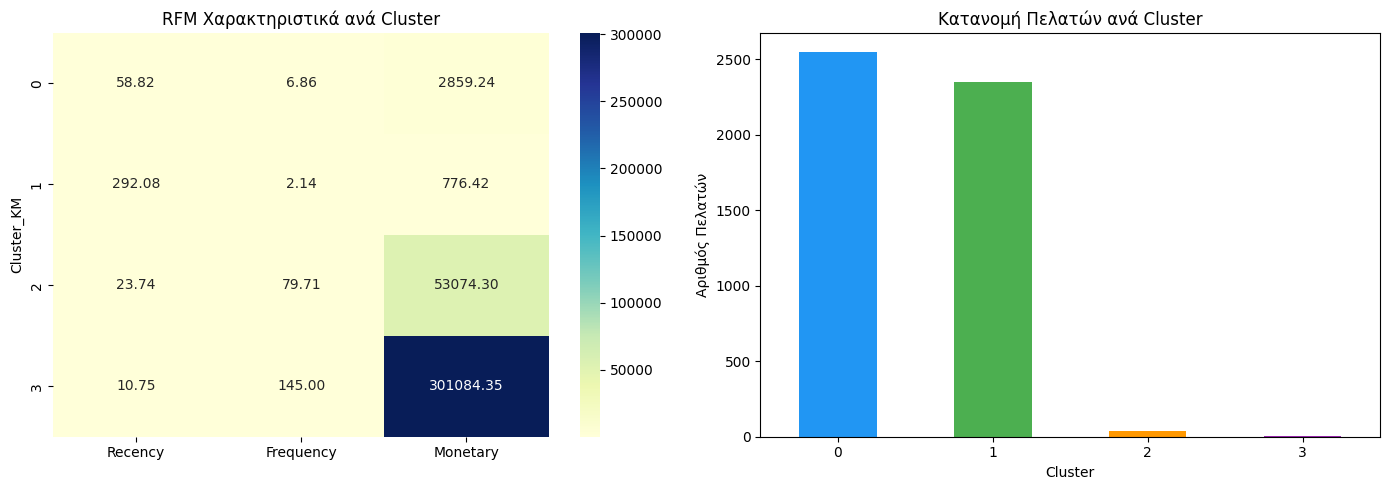

✅ Clustering OK


In [ ]:
# Χρησιμοποιούμε K-Means ως τελικό μοντέλο
cluster_summary = df_model.groupby('Cluster_KM').agg(
    Recency   = ('Recency',   'mean'),
    Frequency = ('Frequency', 'mean'),
    Monetary  = ('Monetary',  'mean'),
    Count     = ('Customer ID', 'count')
).round(2)

print('Μέσες τιμές RFM ανά Cluster:')
print(cluster_summary)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Heatmap
sns.heatmap(cluster_summary[['Recency','Frequency','Monetary']],
            annot=True, cmap='YlGnBu', fmt='.2f', ax=axes[0])
axes[0].set_title('RFM Χαρακτηριστικά ανά Cluster')

# Bar chart κατανομή πελατών
cluster_summary['Count'].plot(kind='bar', ax=axes[1], color=['#2196F3','#4CAF50','#FF9800','#9C27B0'])
axes[1].set_title('Κατανομή Πελατών ανά Cluster')
axes[1].set_xlabel('Cluster')
axes[1].set_ylabel('Αριθμός Πελατών')
axes[1].tick_params(axis='x', rotation=0)

plt.tight_layout()
plt.savefig('clustering_results.png', dpi=150, bbox_inches='tight')
plt.show()
print('✅ Clustering OK')

In [ ]:
from lifetimes import BetaGeoFitter, GammaGammaFitter
from lifetimes.utils import summary_data_from_transaction_data
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from scipy.stats import spearmanr

observation_date = df_feat['InvoiceDate'].max()

summary = summary_data_from_transaction_data(
    df_feat,
    customer_id_col='Customer ID',
    datetime_col='InvoiceDate',
    monetary_value_col='Revenue',
    observation_period_end=observation_date
)
summary_gg = summary[summary['frequency'] > 0].copy()

# BG/NBD
bgf = BetaGeoFitter(penalizer_coef=0.0)
bgf.fit(summary['frequency'], summary['recency'], summary['T'])

# Gamma-Gamma
ggf = GammaGammaFitter(penalizer_coef=0.0)
ggf.fit(summary_gg['frequency'], summary_gg['monetary_value'])

# CLV prediction
clv_bgf = ggf.customer_lifetime_value(
    bgf, summary_gg['frequency'], summary_gg['recency'],
    summary_gg['T'], summary_gg['monetary_value'], time=6, discount_rate=0.01
)
clv_bgf_df = clv_bgf.reset_index()
clv_bgf_df.columns = ['Customer ID', 'CLV_probabilistic']

# Αξιολόγηση
eval_df = df_model.merge(clv_bgf_df, on='Customer ID', how='inner')
y_true = eval_df['Future_CLV']
y_pred = eval_df['CLV_probabilistic']

mae  = mean_absolute_error(y_true, y_pred)
rmse = np.sqrt(mean_squared_error(y_true, y_pred))
mape = np.mean(np.abs((y_true - y_pred) / (y_true + 1))) * 100
r2   = r2_score(y_true, y_pred)
spearman_r, _ = spearmanr(y_true, y_pred)

print('=== BG/NBD + Gamma-Gamma ===')
print(f'  MAE      : {mae:.2f} £')
print(f'  RMSE     : {rmse:.2f} £')
print(f'  MAPE     : {mape:.2f}%')
print(f'  R²       : {r2:.4f}')
print(f'  Spearman : {spearman_r:.4f}')

bgf_results = {'Model':'BG/NBD + Gamma-Gamma', 'MAE':round(mae,2),
               'RMSE':round(rmse,2), 'MAPE':round(mape,2),
               'R2':round(r2,4), 'Spearman':round(spearman_r,4)}

=== BG/NBD + Gamma-Gamma ===
  MAE      : 785.79 £
  RMSE     : 3408.89 £
  MAPE     : 13377.91%
  R²       : 0.7178
  Spearman : 0.6534


In [ ]:
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.model_selection import train_test_split, TimeSeriesSplit, cross_val_score
import xgboost as xgb
import lightgbm as lgb

FEATURES = ['Recency', 'Frequency', 'Monetary_log']
X = df_model[FEATURES].values
y_log = df_model['Future_CLV_log'].values
y_raw = df_model['Future_CLV'].values

X_train, X_test, y_train_log, y_test_log, y_train_raw, y_test_raw = train_test_split(
    X, y_log, y_raw, test_size=0.20, random_state=42
)

tscv = TimeSeriesSplit(n_splits=5)

def evaluate_model(name, y_true_raw, y_pred_log):
    y_pred_raw = np.maximum(np.expm1(y_pred_log), 0)
    mae  = mean_absolute_error(y_true_raw, y_pred_raw)
    rmse = np.sqrt(mean_squared_error(y_true_raw, y_pred_raw))
    mape = np.mean(np.abs((y_true_raw - y_pred_raw) / (y_true_raw + 1))) * 100
    r2   = r2_score(y_true_raw, y_pred_raw)
    spearman_r, _ = spearmanr(y_true_raw, y_pred_raw)
    print(f'\n=== {name} ===')
    print(f'  MAE      : {mae:.2f} £')
    print(f'  RMSE     : {rmse:.2f} £')
    print(f'  MAPE     : {mape:.2f}%')
    print(f'  R²       : {r2:.4f}')
    print(f'  Spearman : {spearman_r:.4f}')
    return {'Model': name, 'MAE': round(mae,2), 'RMSE': round(rmse,2),
            'MAPE': round(mape,2), 'R2': round(r2,4),
            'Spearman': round(spearman_r,4)}, y_pred_raw

print(f'Train: {X_train.shape[0]} | Test: {X_test.shape[0]}')

Train: 3946 | Test: 987


In [ ]:
all_results = [bgf_results]

# 1. Random Forest
rf = RandomForestRegressor(n_estimators=300, max_depth=10, min_samples_split=10,
                           min_samples_leaf=5, max_features='sqrt', random_state=42, n_jobs=-1)
rf.fit(X_train, y_train_log)
rf_metrics, rf_pred_raw = evaluate_model('Random Forest', y_test_raw, rf.predict(X_test))
cv_rf = cross_val_score(rf, X, y_log, cv=tscv, scoring='r2', n_jobs=-1)
print(f'  CV R² (5-fold TS): {cv_rf.mean():.4f} ± {cv_rf.std():.4f}')
rf_metrics['CV_R2'] = f'{cv_rf.mean():.4f} ± {cv_rf.std():.4f}'
all_results.append(rf_metrics)

# 2. XGBoost
xgb_model = xgb.XGBRegressor(n_estimators=500, learning_rate=0.05, max_depth=6,
                               subsample=0.8, colsample_bytree=0.8, min_child_weight=10,
                               reg_alpha=0.1, reg_lambda=1.0, random_state=42, verbosity=0)
xgb_model.fit(X_train, y_train_log)
xgb_metrics, xgb_pred_raw = evaluate_model('XGBoost', y_test_raw, xgb_model.predict(X_test))
cv_xgb = cross_val_score(xgb_model, X, y_log, cv=tscv, scoring='r2', n_jobs=-1)
print(f'  CV R² (5-fold TS): {cv_xgb.mean():.4f} ± {cv_xgb.std():.4f}')
xgb_metrics['CV_R2'] = f'{cv_xgb.mean():.4f} ± {cv_xgb.std():.4f}'
all_results.append(xgb_metrics)

# 3. LightGBM
lgbm_model = lgb.LGBMRegressor(n_estimators=500, learning_rate=0.05, max_depth=6,
                                 num_leaves=31, subsample=0.8, colsample_bytree=0.8,
                                 min_child_samples=20, reg_alpha=0.1, reg_lambda=1.0,
                                 random_state=42, verbose=-1)
lgbm_model.fit(X_train, y_train_log)
lgbm_metrics, lgbm_pred_raw = evaluate_model('LightGBM', y_test_raw, lgbm_model.predict(X_test))
cv_lgbm = cross_val_score(lgbm_model, X, y_log, cv=tscv, scoring='r2', n_jobs=-1)
print(f'  CV R² (5-fold TS): {cv_lgbm.mean():.4f} ± {cv_lgbm.std():.4f}')
lgbm_metrics['CV_R2'] = f'{cv_lgbm.mean():.4f} ± {cv_lgbm.std():.4f}'
all_results.append(lgbm_metrics)

# 4. Gradient Boosting
gbr = GradientBoostingRegressor(n_estimators=300, learning_rate=0.05, max_depth=5,
                                 subsample=0.8, min_samples_leaf=10, random_state=42)
gbr.fit(X_train, y_train_log)
gbr_metrics, gbr_pred_raw = evaluate_model('Gradient Boosting', y_test_raw, gbr.predict(X_test))
cv_gbr = cross_val_score(gbr, X, y_log, cv=tscv, scoring='r2', n_jobs=-1)
print(f'  CV R² (5-fold TS): {cv_gbr.mean():.4f} ± {cv_gbr.std():.4f}')
gbr_metrics['CV_R2'] = f'{cv_gbr.mean():.4f} ± {cv_gbr.std():.4f}'
all_results.append(gbr_metrics)

print('\n✅ Όλα τα ML μοντέλα εκπαιδεύτηκαν!')


=== Random Forest ===
  MAE      : 690.22 £
  RMSE     : 4615.94 £
  MAPE     : 1976.57%
  R²       : 0.4030
  Spearman : 0.6205
  CV R² (5-fold TS): 0.3538 ± 0.0242

=== XGBoost ===
  MAE      : 713.65 £
  RMSE     : 4272.47 £
  MAPE     : 2677.80%
  R²       : 0.4886
  Spearman : 0.5847
  CV R² (5-fold TS): 0.2535 ± 0.0686

=== LightGBM ===
  MAE      : 737.87 £
  RMSE     : 4715.58 £
  MAPE     : 2688.27%
  R²       : 0.3770
  Spearman : 0.5932
  CV R² (5-fold TS): 0.3091 ± 0.0389

=== Gradient Boosting ===
  MAE      : 680.56 £
  RMSE     : 4220.96 £
  MAPE     : 2227.59%
  R²       : 0.5008
  Spearman : 0.6197
  CV R² (5-fold TS): 0.3042 ± 0.0588

✅ Όλα τα ML μοντέλα εκπαιδεύτηκαν!


In [ ]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

# Normalization
from sklearn.preprocessing import StandardScaler
scaler_nn = StandardScaler()
X_train_nn = scaler_nn.fit_transform(X_train)
X_test_nn  = scaler_nn.transform(X_test)

# Αρχιτεκτονική
model_nn = keras.Sequential([
    layers.Dense(64, activation='relu', input_shape=(3,)),
    layers.Dropout(0.2),
    layers.Dense(32, activation='relu'),
    layers.Dropout(0.2),
    layers.Dense(16, activation='relu'),
    layers.Dense(1)
])

model_nn.compile(optimizer='adam', loss='mse', metrics=['mae'])

history = model_nn.fit(
    X_train_nn, y_train_log,
    epochs=100,
    batch_size=32,
    validation_split=0.2,
    verbose=0
)

nn_pred_log = model_nn.predict(X_test_nn).flatten()
nn_metrics, nn_pred_raw = evaluate_model('Neural Network', y_test_raw, nn_pred_log)
nn_metrics['CV_R2'] = 'N/A'
all_results.append(nn_metrics)

print('\n✅ Neural Network εκπαιδεύτηκε!')

31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step

=== Neural Network ===
  MAE      : 834.70 £
  RMSE     : 5445.50 £
  MAPE     : 1397.76%
  R²       : 0.1692
  Spearman : 0.6329

✅ Neural Network εκπαιδεύτηκε!


ΣΥΓΚΡΙΤΙΚΟΣ ΠΙΝΑΚΑΣ ΑΞΙΟΛΟΓΗΣΗΣ ΜΟΝΤΕΛΩΝ CLV
               Model    MAE    RMSE     MAPE     R2  Spearman
BG/NBD + Gamma-Gamma 785.79 3408.89 13377.91 0.7178    0.6534
       Random Forest 690.22 4615.94  1976.57 0.4030    0.6205
             XGBoost 713.65 4272.47  2677.80 0.4886    0.5847
            LightGBM 737.87 4715.58  2688.27 0.3770    0.5932
   Gradient Boosting 680.56 4220.96  2227.59 0.5008    0.6197
      Neural Network 834.70 5445.50  1397.76 0.1692    0.6329


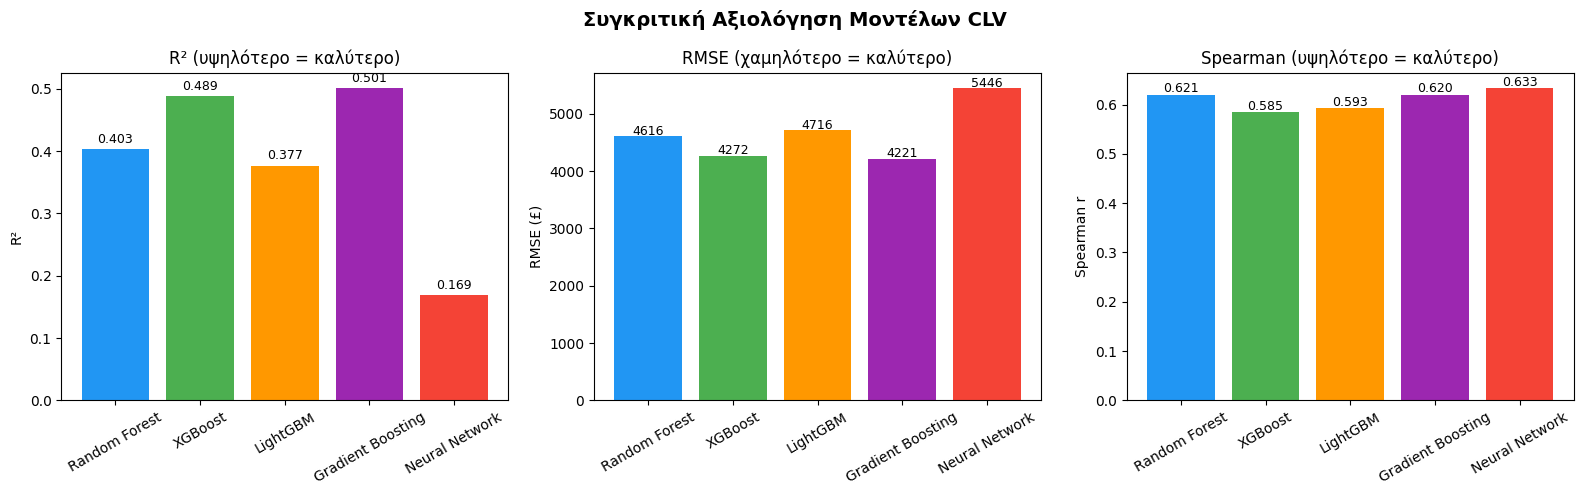

✅ Αποθηκεύτηκαν: model_comparison.png, model_results.csv


In [ ]:
# Συγκριτικός πίνακας
results_df = pd.DataFrame(all_results)
print('='*65)
print('ΣΥΓΚΡΙΤΙΚΟΣ ΠΙΝΑΚΑΣ ΑΞΙΟΛΟΓΗΣΗΣ ΜΟΝΤΕΛΩΝ CLV')
print('='*65)
print(results_df[['Model','MAE','RMSE','MAPE','R2','Spearman']].to_string(index=False))
print('='*65)

# Γράφημα σύγκρισης
ml_df = results_df[results_df['Model'] != 'BG/NBD + Gamma-Gamma'].copy()
colors = ['#2196F3','#4CAF50','#FF9800','#9C27B0','#F44336']

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
fig.suptitle('Συγκριτική Αξιολόγηση Μοντέλων CLV', fontsize=14, fontweight='bold')

# R²
axes[0].bar(ml_df['Model'], ml_df['R2'], color=colors)
axes[0].set_title('R² (υψηλότερο = καλύτερο)')
axes[0].set_ylabel('R²')
axes[0].tick_params(axis='x', rotation=30)
for i, v in enumerate(ml_df['R2']):
    axes[0].text(i, v+0.01, f'{v:.3f}', ha='center', fontsize=9)

# RMSE
axes[1].bar(ml_df['Model'], ml_df['RMSE'], color=colors)
axes[1].set_title('RMSE (χαμηλότερο = καλύτερο)')
axes[1].set_ylabel('RMSE (£)')
axes[1].tick_params(axis='x', rotation=30)
for i, v in enumerate(ml_df['RMSE']):
    axes[1].text(i, v+20, f'{v:.0f}', ha='center', fontsize=9)

# Spearman
axes[2].bar(ml_df['Model'], ml_df['Spearman'], color=colors)
axes[2].set_title('Spearman (υψηλότερο = καλύτερο)')
axes[2].set_ylabel('Spearman r')
axes[2].tick_params(axis='x', rotation=30)
for i, v in enumerate(ml_df['Spearman']):
    axes[2].text(i, v+0.005, f'{v:.3f}', ha='center', fontsize=9)

plt.tight_layout()
plt.savefig('model_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

results_df.to_csv('model_results.csv', index=False)
print('✅ Αποθηκεύτηκαν: model_comparison.png, model_results.csv')

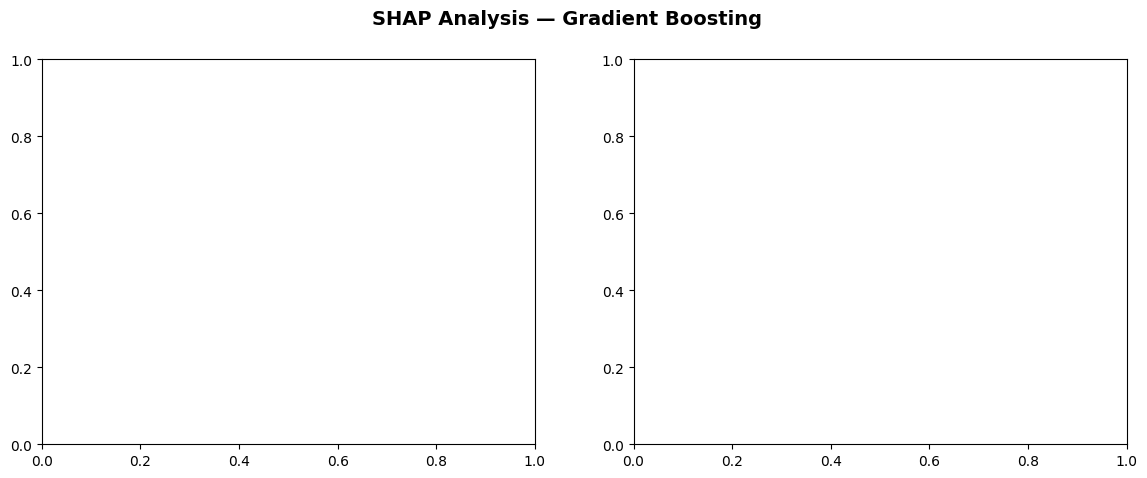

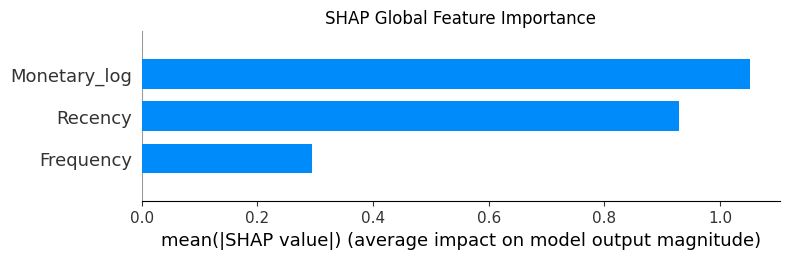

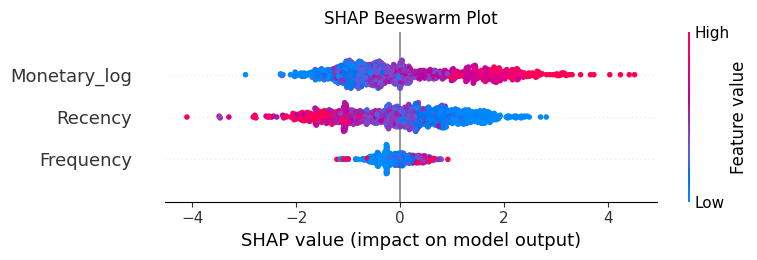

✅ SHAP Analysis OK


In [ ]:
import shap

# SHAP στο Gradient Boosting (καλύτερο R²)
explainer = shap.TreeExplainer(gbr)
shap_values = explainer.shap_values(X_test)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('SHAP Analysis — Gradient Boosting', fontsize=14, fontweight='bold')

# Summary bar plot
plt.figure(figsize=(8, 5))
shap.summary_plot(shap_values, X_test, feature_names=FEATURES,
                  plot_type='bar', show=False)
plt.title('SHAP Global Feature Importance')
plt.tight_layout()
plt.savefig('shap_bar.png', dpi=150, bbox_inches='tight')
plt.show()

# Beeswarm plot
plt.figure(figsize=(8, 5))
shap.summary_plot(shap_values, X_test, feature_names=FEATURES, show=False)
plt.title('SHAP Beeswarm Plot')
plt.tight_layout()
plt.savefig('shap_beeswarm.png', dpi=150, bbox_inches='tight')
plt.show()

print('✅ SHAP Analysis OK')

In [ ]:
from google.colab import files

# Κατέβασε όλα τα γραφήματα και αποτελέσματα
files.download('EDA_plots.png')
files.download('clustering_results.png')
files.download('model_comparison.png')
files.download('shap_bar.png')
files.download('shap_beeswarm.png')
files.download('model_results.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

...

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

=== Περιγραφικά Στατιστικά RFM ===
       Recency  Frequency   Monetary
count  4933.00    4933.00    4933.00
mean    169.56       5.24    2465.96
std     141.92      10.13   10907.75
min       1.00       1.00       2.90
25%      44.00       1.00     317.60
50%     161.00       3.00     774.87
75%     244.00       6.00    2001.07
max     547.00     258.00  413806.46


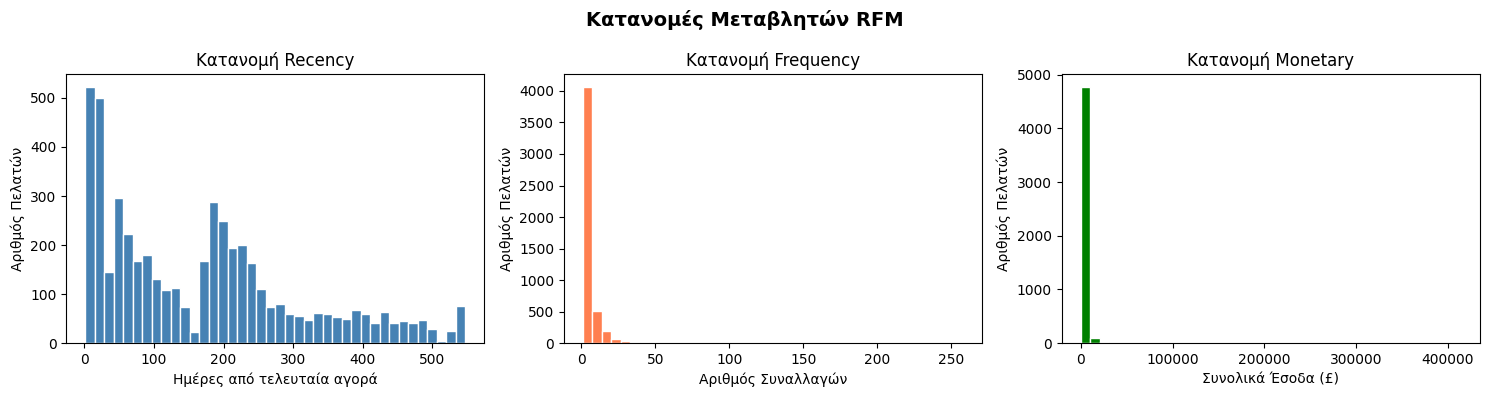

✅ OK


In [ ]:
# Περιγραφικά στατιστικά
print('=== Περιγραφικά Στατιστικά RFM ===')
print(df_model[['Recency','Frequency','Monetary']].describe().round(2))

# Κατανομές R, F, M
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
fig.suptitle('Κατανομές Μεταβλητών RFM', fontsize=14, fontweight='bold')

axes[0].hist(df_model['Recency'], bins=40, color='steelblue', edgecolor='white')
axes[0].set_title('Κατανομή Recency')
axes[0].set_xlabel('Ημέρες από τελευταία αγορά')
axes[0].set_ylabel('Αριθμός Πελατών')

axes[1].hist(df_model['Frequency'], bins=40, color='coral', edgecolor='white')
axes[1].set_title('Κατανομή Frequency')
axes[1].set_xlabel('Αριθμός Συναλλαγών')
axes[1].set_ylabel('Αριθμός Πελατών')

axes[2].hist(df_model['Monetary'], bins=40, color='green', edgecolor='white')
axes[2].set_title('Κατανομή Monetary')
axes[2].set_xlabel('Συνολικά Έσοδα (£)')
axes[2].set_ylabel('Αριθμός Πελατών')

plt.tight_layout()
plt.savefig('rfm_distributions.png', dpi=150, bbox_inches='tight')
plt.show()
print('✅ OK')

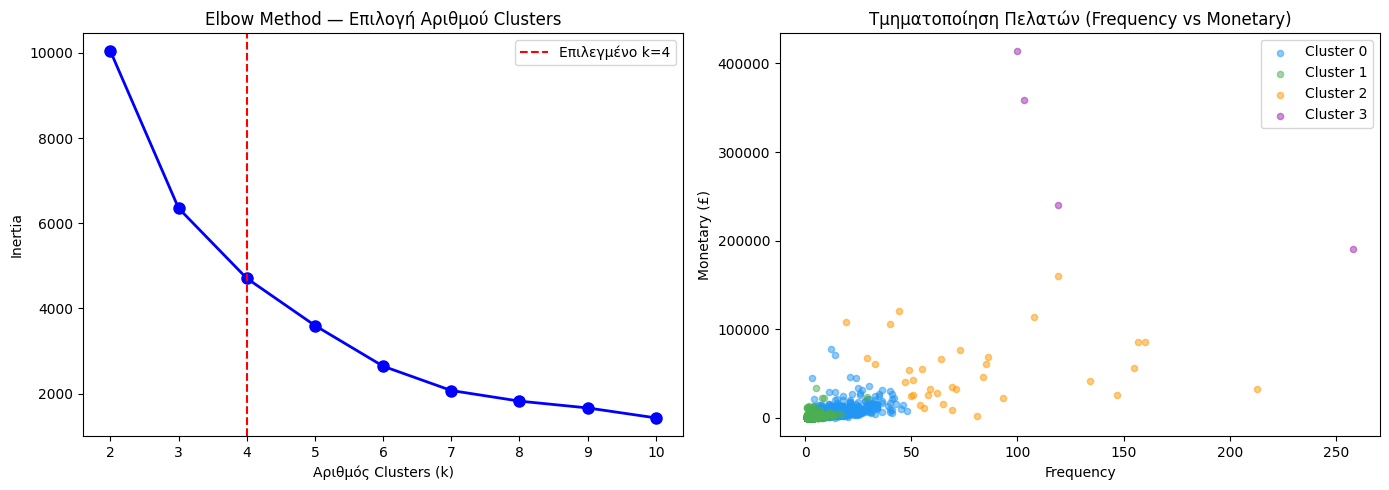

✅ OK


In [ ]:
# Elbow Method για K-Means
inertias = []
k_range = range(2, 11)
for k in k_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(rfm_scaled)
    inertias.append(km.inertia_)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Elbow plot
axes[0].plot(k_range, inertias, 'bo-', linewidth=2, markersize=8)
axes[0].axvline(x=4, color='red', linestyle='--', label='Επιλεγμένο k=4')
axes[0].set_title('Elbow Method — Επιλογή Αριθμού Clusters')
axes[0].set_xlabel('Αριθμός Clusters (k)')
axes[0].set_ylabel('Inertia')
axes[0].legend()

# Scatter plot clusters
colors = ['#2196F3','#4CAF50','#FF9800','#9C27B0']
for cluster in range(4):
    mask = df_model['Cluster_KM'] == cluster
    axes[1].scatter(df_model[mask]['Frequency'],
                    df_model[mask]['Monetary'],
                    c=colors[cluster], label=f'Cluster {cluster}',
                    alpha=0.5, s=20)
axes[1].set_title('Τμηματοποίηση Πελατών (Frequency vs Monetary)')
axes[1].set_xlabel('Frequency')
axes[1].set_ylabel('Monetary (£)')
axes[1].legend()

plt.tight_layout()
plt.savefig('elbow_clusters.png', dpi=150, bbox_inches='tight')
plt.show()
print('✅ OK')

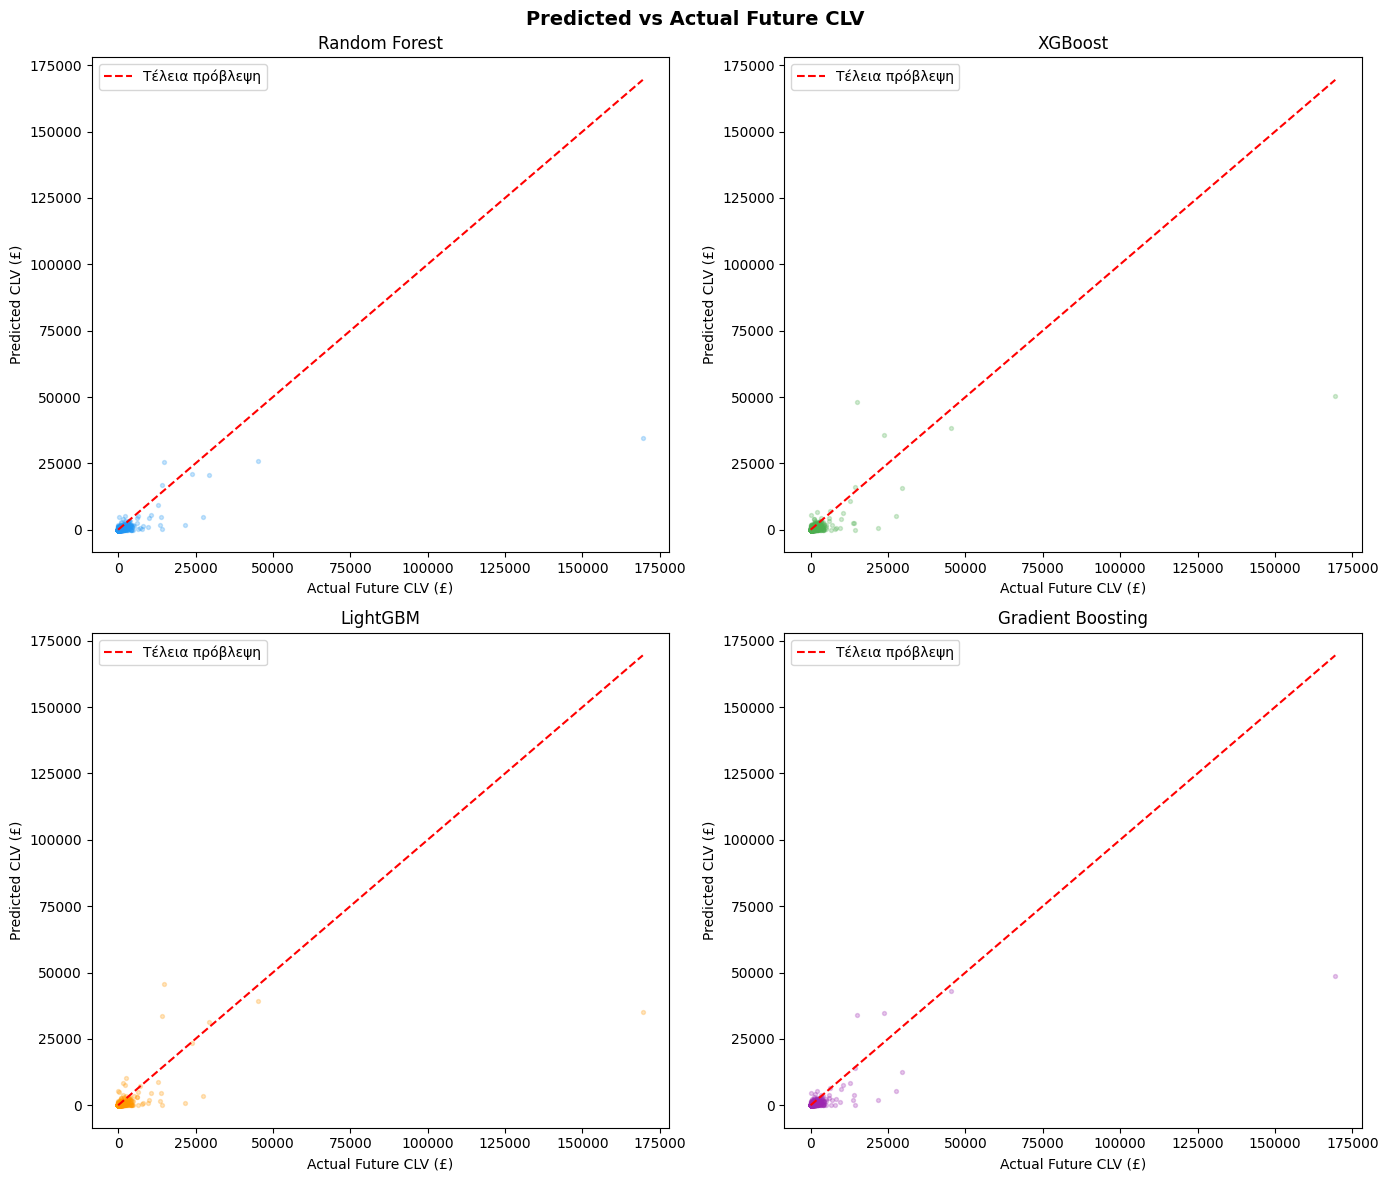

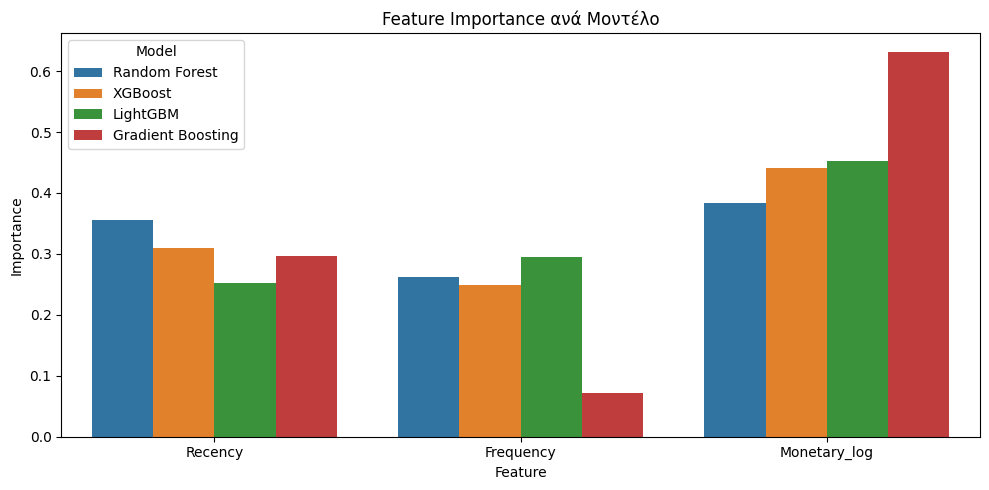

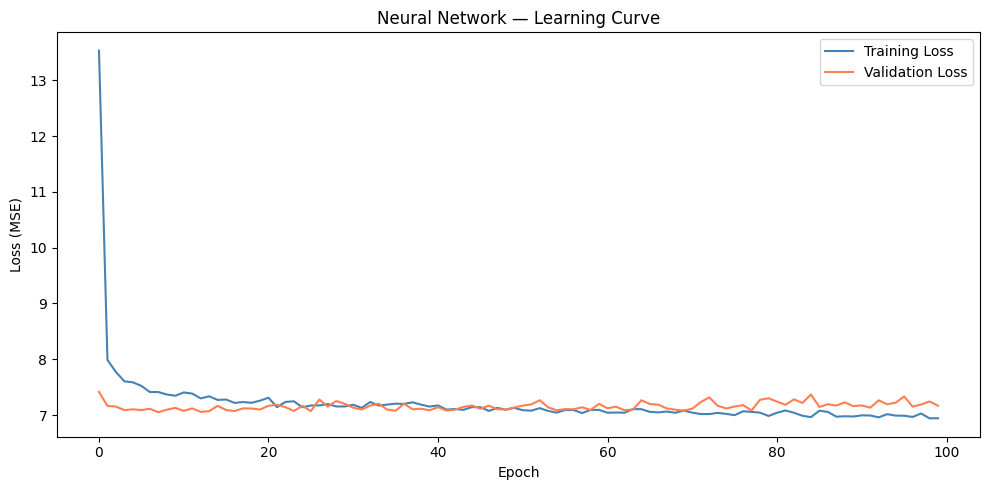

✅ OK


In [ ]:
# 1. Predicted vs Actual (4 μοντέλα)
fig, axes = plt.subplots(2, 2, figsize=(14, 12))
fig.suptitle('Predicted vs Actual Future CLV', fontsize=14, fontweight='bold')

models_info = [
    ('Random Forest', rf_pred_raw, '#2196F3'),
    ('XGBoost', xgb_pred_raw, '#4CAF50'),
    ('LightGBM', lgbm_pred_raw, '#FF9800'),
    ('Gradient Boosting', gbr_pred_raw, '#9C27B0')
]

for ax, (name, y_pred, color) in zip(axes.flat, models_info):
    ax.scatter(y_test_raw, y_pred, alpha=0.25, s=8, color=color)
    max_val = max(y_test_raw.max(), y_pred.max())
    ax.plot([0, max_val], [0, max_val], 'r--', linewidth=1.5, label='Τέλεια πρόβλεψη')
    ax.set_xlabel('Actual Future CLV (£)')
    ax.set_ylabel('Predicted CLV (£)')
    ax.set_title(name)
    ax.legend()

plt.tight_layout()
plt.savefig('predicted_vs_actual.png', dpi=150, bbox_inches='tight')
plt.show()

# 2. Feature Importance σύγκριση
feat_names = FEATURES
imp_df = pd.DataFrame({
    'Feature': feat_names,
    'Random Forest': rf.feature_importances_,
    'XGBoost': xgb_model.feature_importances_,
    'LightGBM': lgbm_model.feature_importances_ / lgbm_model.feature_importances_.sum(),
    'Gradient Boosting': gbr.feature_importances_
})
imp_melted = imp_df.melt(id_vars='Feature', var_name='Model', value_name='Importance')

plt.figure(figsize=(10, 5))
sns.barplot(data=imp_melted, x='Feature', y='Importance', hue='Model')
plt.title('Feature Importance ανά Μοντέλο')
plt.ylabel('Importance')
plt.tight_layout()
plt.savefig('feature_importance.png', dpi=150, bbox_inches='tight')
plt.show()

# 3. Neural Network Learning Curve
plt.figure(figsize=(10, 5))
plt.plot(history.history['loss'], label='Training Loss', color='steelblue')
plt.plot(history.history['val_loss'], label='Validation Loss', color='coral')
plt.title('Neural Network — Learning Curve')
plt.xlabel('Epoch')
plt.ylabel('Loss (MSE)')
plt.legend()
plt.tight_layout()
plt.savefig('nn_learning_curve.png', dpi=150, bbox_inches='tight')
plt.show()

print('✅ OK')

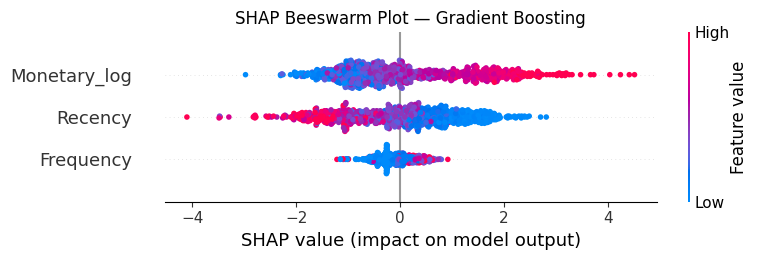

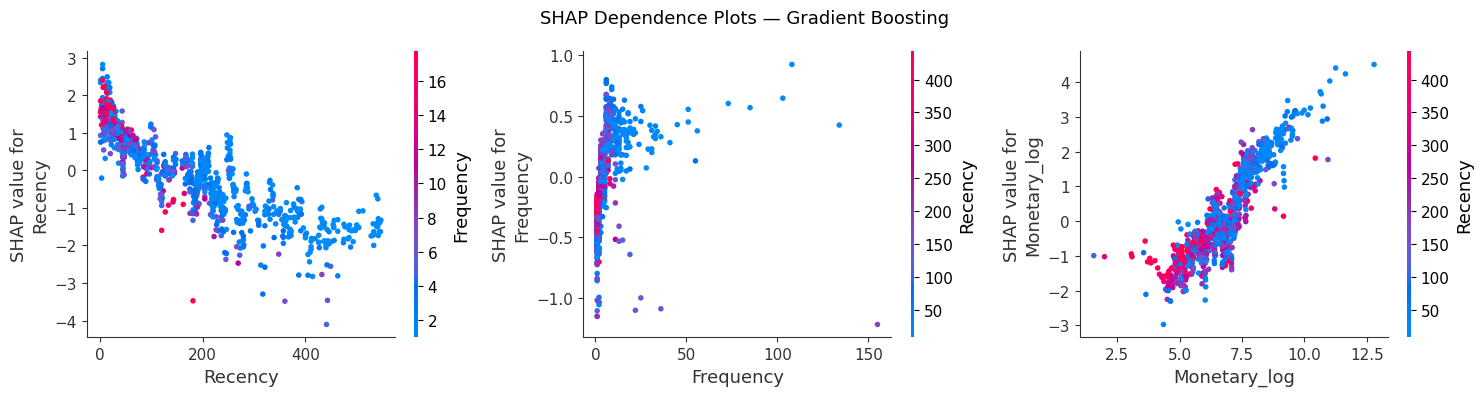

=== Top 10 Πελάτες βάσει Ensemble CLV ===
 Customer ID  Recency  Frequency  Monetary  Future_CLV  CLV_Ensemble
       15311        5        160  85669.95    31101.21      44138.08
       14911        6        258 190947.35   105025.28      42251.35
       14646        6        103 359109.62   169492.90      42131.68
       14156       16        119 240473.97    73472.40      40556.77
       13089        8        157  85851.97    30885.89      39247.56
       13798        5         85  60975.54    14861.33      38322.46
       18102       15        100 413806.46   195015.19      38256.79
       16029        8         73  76960.56    45248.58      36597.58
       13694        1        119 159642.54    36840.27      35910.78
       17949        1         86  69176.40    49451.68      34802.38


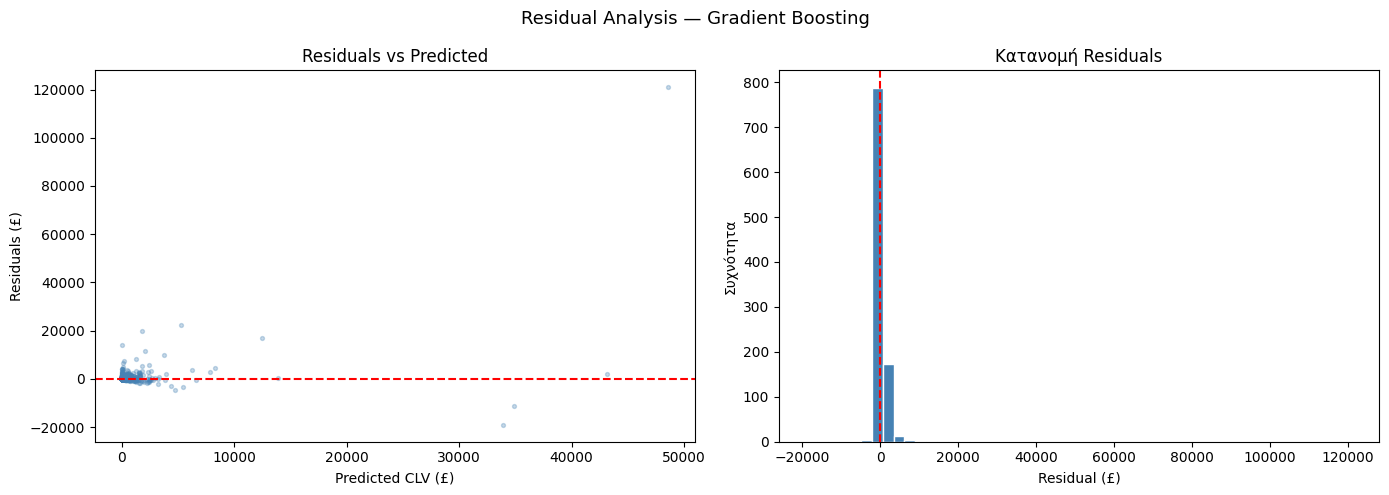

✅ OK


In [ ]:
import shap

# SHAP beeswarm
plt.figure(figsize=(10, 5))
shap.summary_plot(shap_values, X_test, feature_names=FEATURES, show=False)
plt.title('SHAP Beeswarm Plot — Gradient Boosting')
plt.tight_layout()
plt.savefig('shap_beeswarm.png', dpi=150, bbox_inches='tight')
plt.show()

# SHAP dependence plots
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
fig.suptitle('SHAP Dependence Plots — Gradient Boosting', fontsize=13)
for i, feat in enumerate(FEATURES):
    shap.dependence_plot(i, shap_values, X_test, feature_names=FEATURES, ax=axes[i], show=False)
plt.tight_layout()
plt.savefig('shap_dependence.png', dpi=150, bbox_inches='tight')
plt.show()

# Top 10 πελάτες βάσει προβλεπόμενου CLV
X_full = df_model[FEATURES].values
df_model['CLV_RF']   = np.maximum(np.expm1(rf.predict(X_full)), 0).round(2)
df_model['CLV_XGB']  = np.maximum(np.expm1(xgb_model.predict(X_full)), 0).round(2)
df_model['CLV_LGBM'] = np.maximum(np.expm1(lgbm_model.predict(X_full)), 0).round(2)
df_model['CLV_GBR']  = np.maximum(np.expm1(gbr.predict(X_full)), 0).round(2)
df_model['CLV_Ensemble'] = df_model[['CLV_RF','CLV_XGB','CLV_LGBM','CLV_GBR']].mean(axis=1).round(2)

print('=== Top 10 Πελάτες βάσει Ensemble CLV ===')
print(df_model.nlargest(10, 'CLV_Ensemble')[
    ['Customer ID','Recency','Frequency','Monetary','Future_CLV','CLV_Ensemble']
].to_string(index=False))

# Residual Analysis (Gradient Boosting)
residuals = y_test_raw - gbr_pred_raw

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Residual Analysis — Gradient Boosting', fontsize=13)

axes[0].scatter(gbr_pred_raw, residuals, alpha=0.3, s=8, color='steelblue')
axes[0].axhline(y=0, color='red', linestyle='--')
axes[0].set_xlabel('Predicted CLV (£)')
axes[0].set_ylabel('Residuals (£)')
axes[0].set_title('Residuals vs Predicted')

axes[1].hist(residuals, bins=50, color='steelblue', edgecolor='white')
axes[1].axvline(x=0, color='red', linestyle='--')
axes[1].set_xlabel('Residual (£)')
axes[1].set_ylabel('Συχνότητα')
axes[1].set_title('Κατανομή Residuals')

plt.tight_layout()
plt.savefig('residual_analysis.png', dpi=150, bbox_inches='tight')
plt.show()

print('✅ OK')

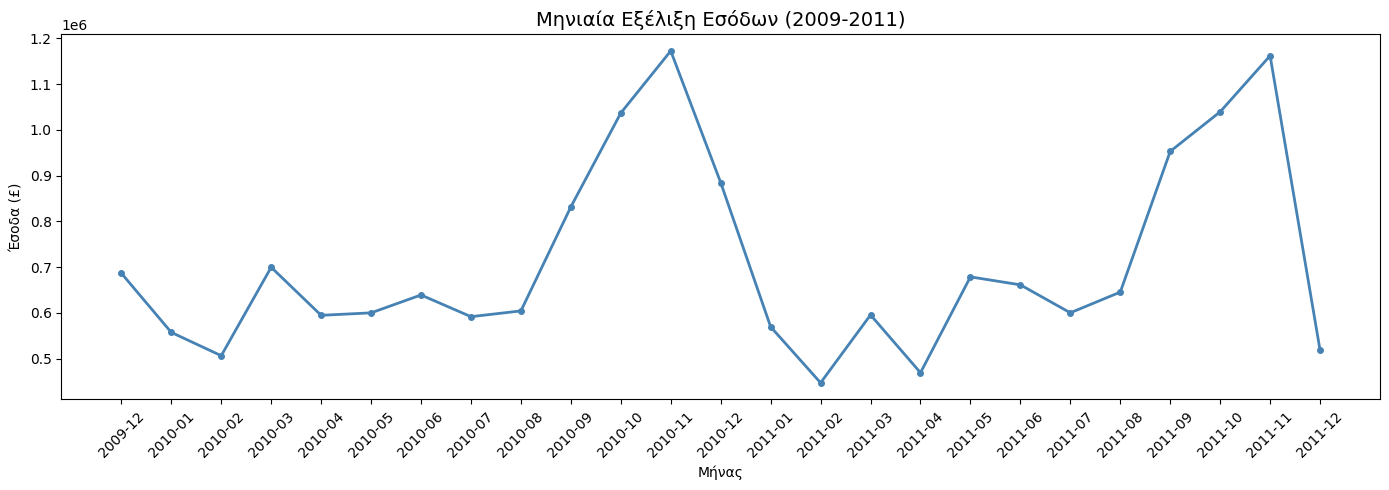

✅ Διάγραμμα 4.1 OK


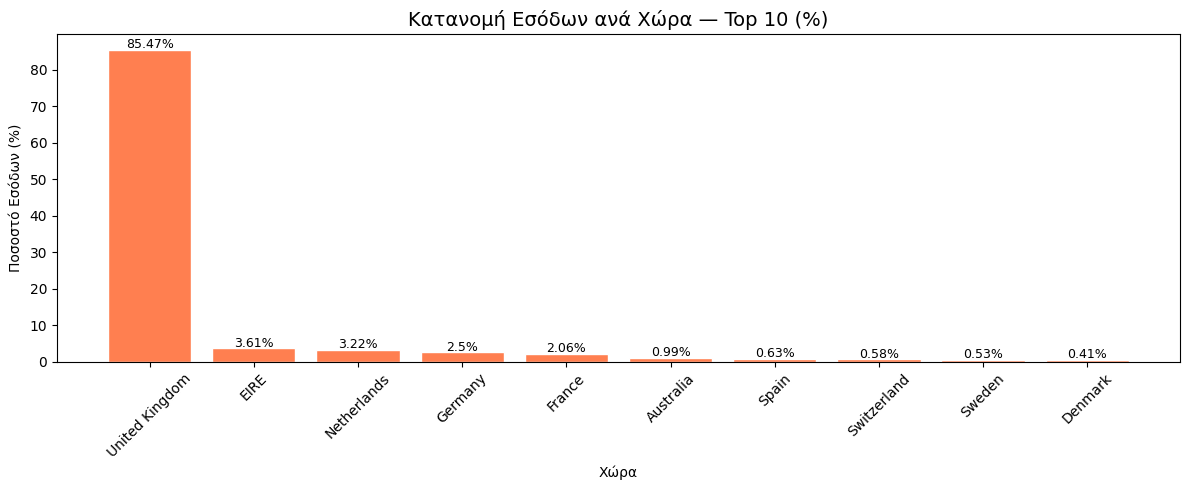

✅ Διάγραμμα 4.2 OK


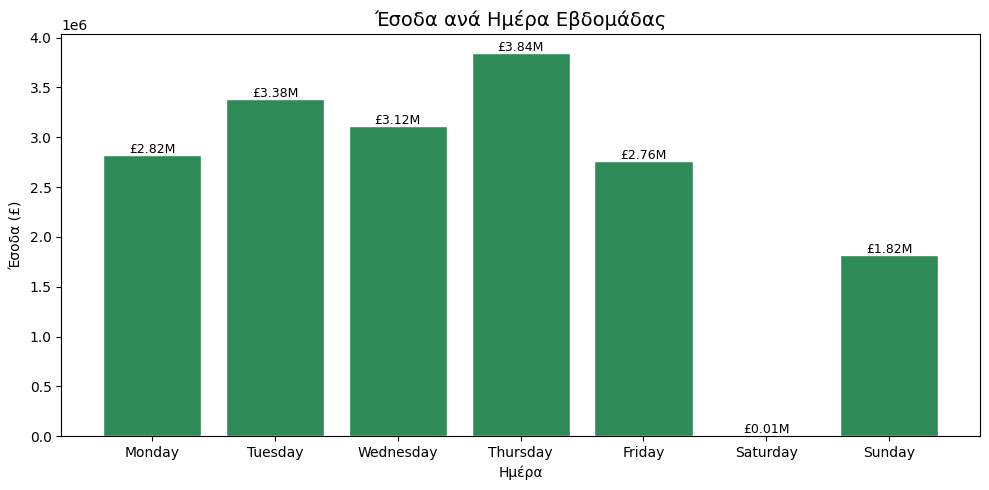

✅ Διάγραμμα 4.3 OK


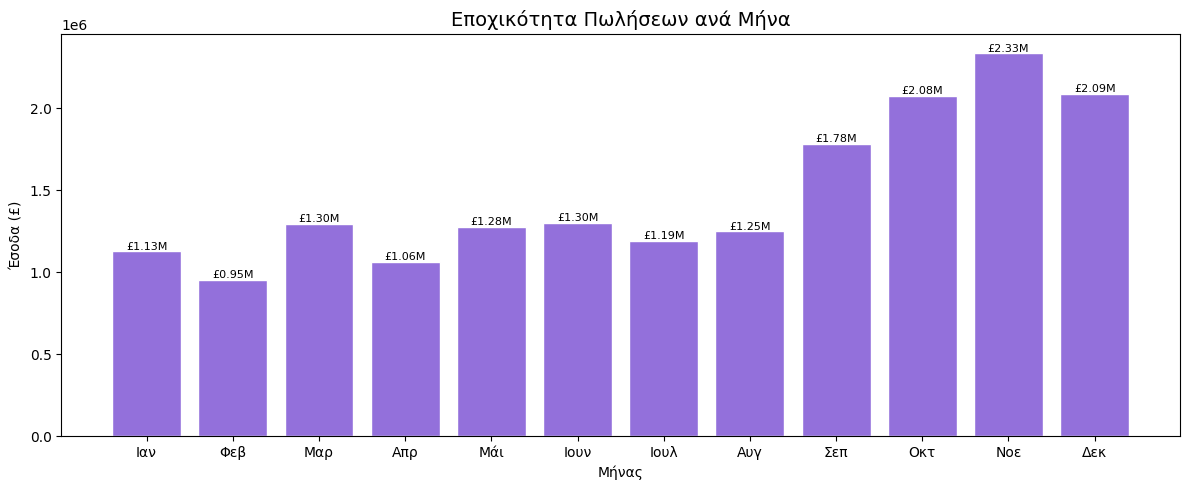

✅ Διάγραμμα 4.4 OK


In [ ]:
# Διάγραμμα 4.1 — Μηνιαία εξέλιξη εσόδων
df['YearMonth'] = df['InvoiceDate'].dt.to_period('M')
monthly = df.groupby('YearMonth')['Revenue'].sum()

plt.figure(figsize=(14, 5))
plt.plot(monthly.index.astype(str), monthly.values, color='steelblue', linewidth=2, marker='o', markersize=4)
plt.title('Μηνιαία Εξέλιξη Εσόδων (2009-2011)', fontsize=14)
plt.xlabel('Μήνας')
plt.ylabel('Έσοδα (£)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig('diagram_4_1_monthly_revenue.png', dpi=150, bbox_inches='tight')
plt.show()
print('✅ Διάγραμμα 4.1 OK')

# Διάγραμμα 4.2 — Γεωγραφική κατανομή
country = df.groupby('Country')['Revenue'].sum().sort_values(ascending=False).head(10)
country_share = (country / country.sum() * 100).round(2)

plt.figure(figsize=(12, 5))
bars = plt.bar(country_share.index, country_share.values, color='coral', edgecolor='white')
plt.title('Κατανομή Εσόδων ανά Χώρα — Top 10 (%)', fontsize=14)
plt.xlabel('Χώρα')
plt.ylabel('Ποσοστό Εσόδων (%)')
plt.xticks(rotation=45)
for bar, val in zip(bars, country_share.values):
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5,
             f'{val}%', ha='center', fontsize=9)
plt.tight_layout()
plt.savefig('diagram_4_2_country_revenue.png', dpi=150, bbox_inches='tight')
plt.show()
print('✅ Διάγραμμα 4.2 OK')

# Διάγραμμα 4.3 — Έσοδα ανά ημέρα εβδομάδας
df['DayOfWeek'] = df['InvoiceDate'].dt.day_name()
order = ['Monday','Tuesday','Wednesday','Thursday','Friday','Saturday','Sunday']
weekly = df.groupby('DayOfWeek')['Revenue'].sum().reindex(order)

plt.figure(figsize=(10, 5))
bars = plt.bar(weekly.index, weekly.values, color='seagreen', edgecolor='white')
plt.title('Έσοδα ανά Ημέρα Εβδομάδας', fontsize=14)
plt.xlabel('Ημέρα')
plt.ylabel('Έσοδα (£)')
for bar, val in zip(bars, weekly.values):
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 20000,
             f'£{val/1e6:.2f}M', ha='center', fontsize=9)
plt.tight_layout()
plt.savefig('diagram_4_3_weekly_revenue.png', dpi=150, bbox_inches='tight')
plt.show()
print('✅ Διάγραμμα 4.3 OK')

# Διάγραμμα 4.4 — Εποχικότητα
df['Month'] = df['InvoiceDate'].dt.month
seasonal = df.groupby('Month')['Revenue'].sum()
month_names = ['Ιαν','Φεβ','Μαρ','Απρ','Μάι','Ιουν','Ιουλ','Αυγ','Σεπ','Οκτ','Νοε','Δεκ']

plt.figure(figsize=(12, 5))
bars = plt.bar(range(1,13), seasonal.values, color='mediumpurple', edgecolor='white')
plt.title('Εποχικότητα Πωλήσεων ανά Μήνα', fontsize=14)
plt.xlabel('Μήνας')
plt.ylabel('Έσοδα (£)')
plt.xticks(range(1,13), month_names)
for bar, val in zip(bars, seasonal.values):
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 10000,
             f'£{val/1e6:.2f}M', ha='center', fontsize=8)
plt.tight_layout()
plt.savefig('diagram_4_4_seasonality.png', dpi=150, bbox_inches='tight')
plt.show()
print('✅ Διάγραμμα 4.4 OK')

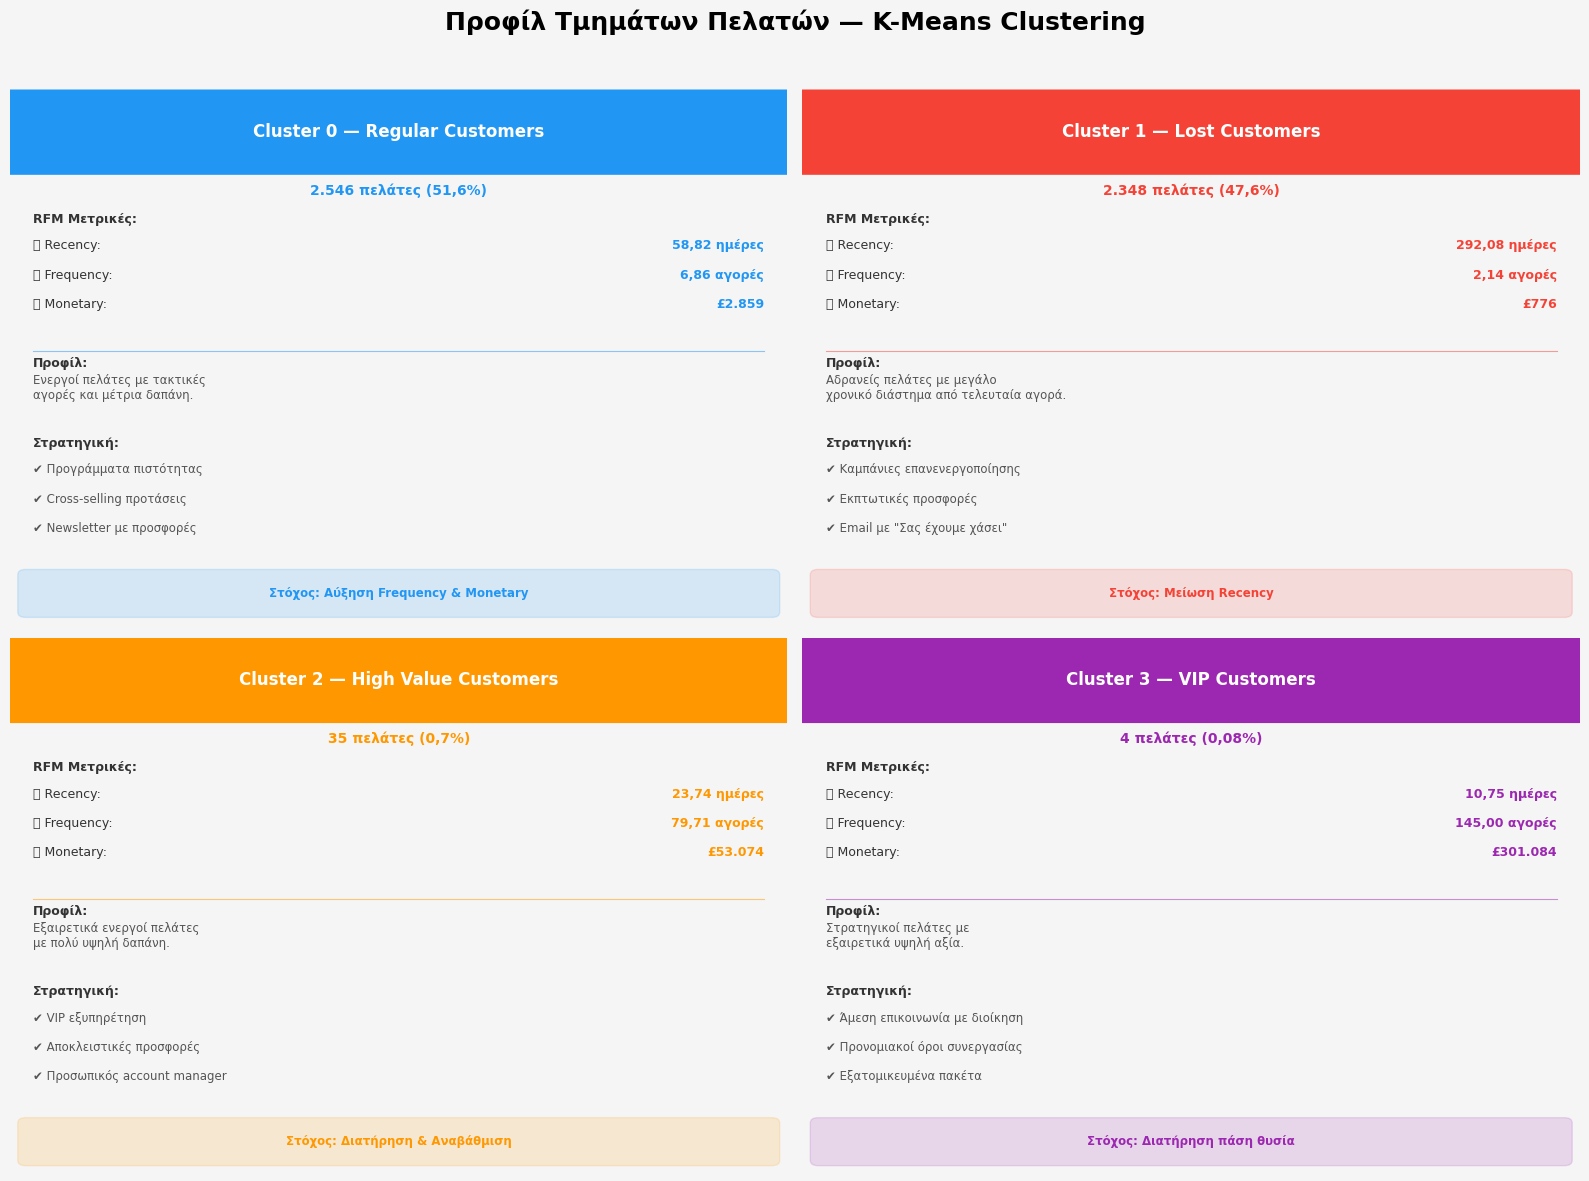

✅ Dashboard OK


In [ ]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.patches import FancyBboxPatch

fig, axes = plt.subplots(2, 2, figsize=(16, 12))
fig.patch.set_facecolor('#F5F5F5')
fig.suptitle('Προφίλ Τμημάτων Πελατών — K-Means Clustering',
             fontsize=18, fontweight='bold', y=0.98)

clusters = [
    {
        'title': 'Cluster 0 — Regular Customers',
        'color': '#2196F3',
        'light': '#E3F2FD',
        'count': '2.546 πελάτες (51,6%)',
        'metrics': [
            ('Recency', '58,82 ημέρες', '🟢'),
            ('Frequency', '6,86 αγορές', '🟡'),
            ('Monetary', '£2.859', '🟡'),
        ],
        'profile': 'Ενεργοί πελάτες με τακτικές\nαγορές και μέτρια δαπάνη.',
        'strategy': [
            '✔ Προγράμματα πιστότητας',
            '✔ Cross-selling προτάσεις',
            '✔ Newsletter με προσφορές',
        ],
        'kpi': 'Στόχος: Αύξηση Frequency & Monetary'
    },
    {
        'title': 'Cluster 1 — Lost Customers',
        'color': '#F44336',
        'light': '#FFEBEE',
        'count': '2.348 πελάτες (47,6%)',
        'metrics': [
            ('Recency', '292,08 ημέρες', '🔴'),
            ('Frequency', '2,14 αγορές', '🔴'),
            ('Monetary', '£776', '🔴'),
        ],
        'profile': 'Αδρανείς πελάτες με μεγάλο\nχρονικό διάστημα από τελευταία αγορά.',
        'strategy': [
            '✔ Καμπάνιες επανενεργοποίησης',
            '✔ Εκπτωτικές προσφορές',
            '✔ Email με "Σας έχουμε χάσει"',
        ],
        'kpi': 'Στόχος: Μείωση Recency'
    },
    {
        'title': 'Cluster 2 — High Value Customers',
        'color': '#FF9800',
        'light': '#FFF3E0',
        'count': '35 πελάτες (0,7%)',
        'metrics': [
            ('Recency', '23,74 ημέρες', '🟢'),
            ('Frequency', '79,71 αγορές', '🟢'),
            ('Monetary', '£53.074', '🟢'),
        ],
        'profile': 'Εξαιρετικά ενεργοί πελάτες\nμε πολύ υψηλή δαπάνη.',
        'strategy': [
            '✔ VIP εξυπηρέτηση',
            '✔ Αποκλειστικές προσφορές',
            '✔ Προσωπικός account manager',
        ],
        'kpi': 'Στόχος: Διατήρηση & Αναβάθμιση'
    },
    {
        'title': 'Cluster 3 — VIP Customers',
        'color': '#9C27B0',
        'light': '#F3E5F5',
        'count': '4 πελάτες (0,08%)',
        'metrics': [
            ('Recency', '10,75 ημέρες', '🟢'),
            ('Frequency', '145,00 αγορές', '🟢'),
            ('Monetary', '£301.084', '🟢'),
        ],
        'profile': 'Στρατηγικοί πελάτες με\nεξαιρετικά υψηλή αξία.',
        'strategy': [
            '✔ Άμεση επικοινωνία με διοίκηση',
            '✔ Προνομιακοί όροι συνεργασίας',
            '✔ Εξατομικευμένα πακέτα',
        ],
        'kpi': 'Στόχος: Διατήρηση πάση θυσία'
    },
]

for ax, cluster in zip(axes.flat, clusters):
    ax.set_facecolor(cluster['light'])
    ax.set_xlim(0, 10)
    ax.set_ylim(0, 10)
    ax.axis('off')

    # Τίτλος cluster
    ax.add_patch(FancyBboxPatch((0, 8.5), 10, 1.4,
                                boxstyle="round,pad=0.1",
                                facecolor=cluster['color'], edgecolor='none'))
    ax.text(5, 9.2, cluster['title'], ha='center', va='center',
            fontsize=12, fontweight='bold', color='white')

    # Πλήθος πελατών
    ax.text(5, 8.1, cluster['count'], ha='center', va='center',
            fontsize=10, color=cluster['color'], fontweight='bold')

    # Metrics
    ax.text(0.3, 7.5, 'RFM Μετρικές:', fontsize=9, fontweight='bold', color='#333333')
    for i, (metric, value, icon) in enumerate(cluster['metrics']):
        ax.text(0.3, 7.0 - i*0.55, f'{icon} {metric}:', fontsize=9, color='#333333')
        ax.text(9.7, 7.0 - i*0.55, value, fontsize=9, color=cluster['color'],
                fontweight='bold', ha='right')

    # Διαχωριστική γραμμή
    ax.axhline(y=5.1, xmin=0.03, xmax=0.97, color=cluster['color'], linewidth=0.8, alpha=0.5)

    # Προφίλ
    ax.text(0.3, 4.8, 'Προφίλ:', fontsize=9, fontweight='bold', color='#333333')
    ax.text(0.3, 4.2, cluster['profile'], fontsize=8.5, color='#555555')

    # Στρατηγική
    ax.text(0.3, 3.3, 'Στρατηγική:', fontsize=9, fontweight='bold', color='#333333')
    for i, action in enumerate(cluster['strategy']):
        ax.text(0.3, 2.8 - i*0.55, action, fontsize=8.5, color='#555555')

    # KPI
    ax.add_patch(FancyBboxPatch((0.2, 0.2), 9.6, 0.7,
                                boxstyle="round,pad=0.1",
                                facecolor=cluster['color'], alpha=0.15, edgecolor=cluster['color']))
    ax.text(5, 0.55, cluster['kpi'], ha='center', va='center',
            fontsize=8.5, color=cluster['color'], fontweight='bold')

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.savefig('cluster_profiles_dashboard.png', dpi=150, bbox_inches='tight',
            facecolor='#F5F5F5')
plt.show()
print('✅ Dashboard OK')

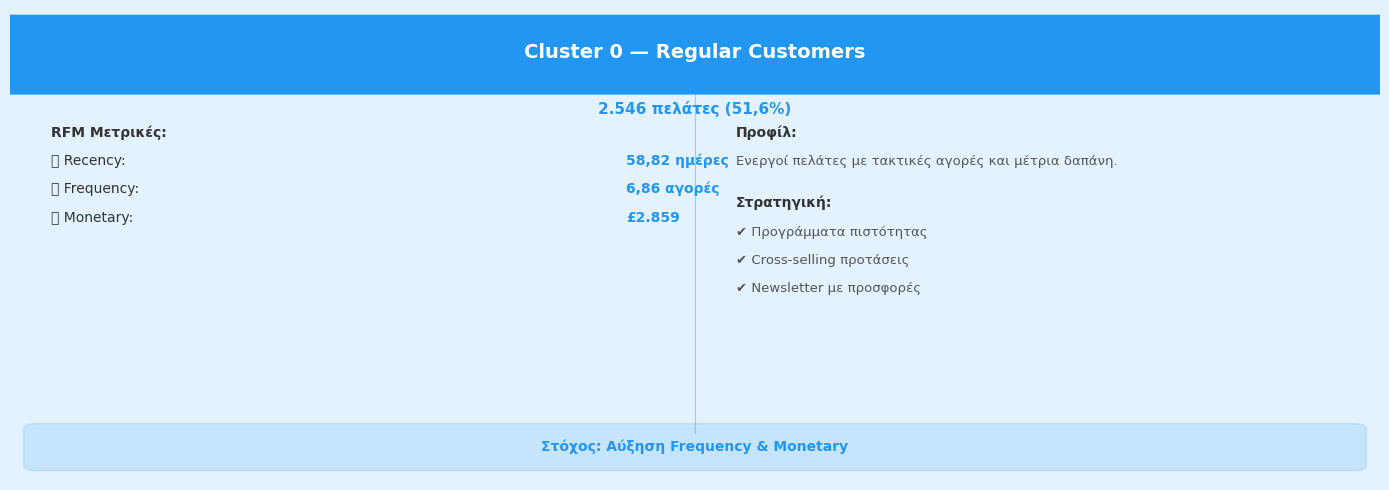

✅ Cluster 0 αποθηκεύτηκε: cluster_0_profile.png


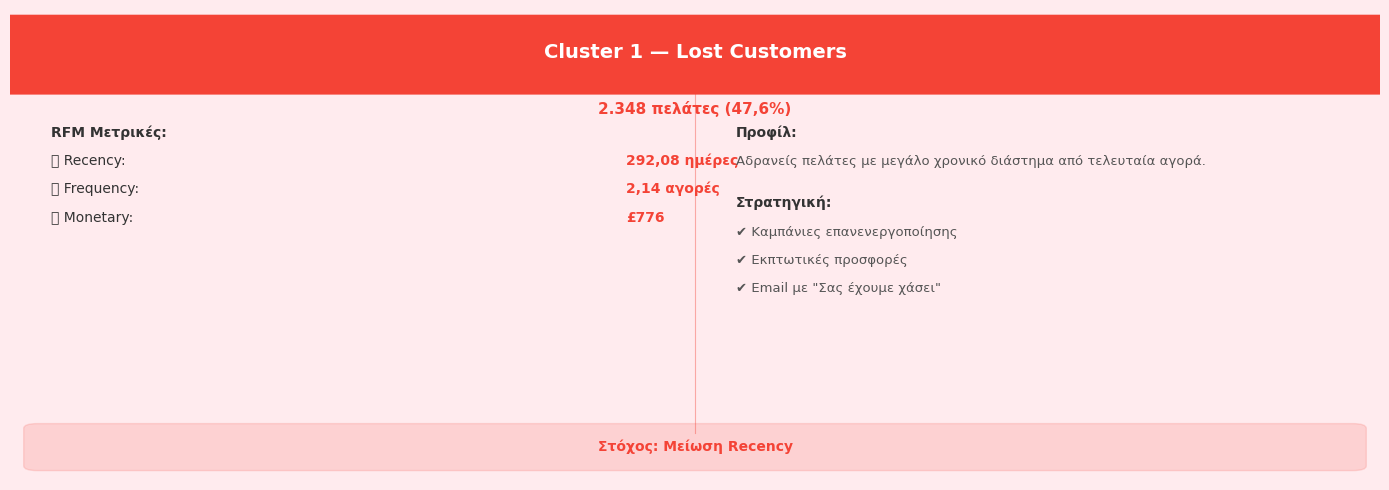

✅ Cluster 1 αποθηκεύτηκε: cluster_1_profile.png


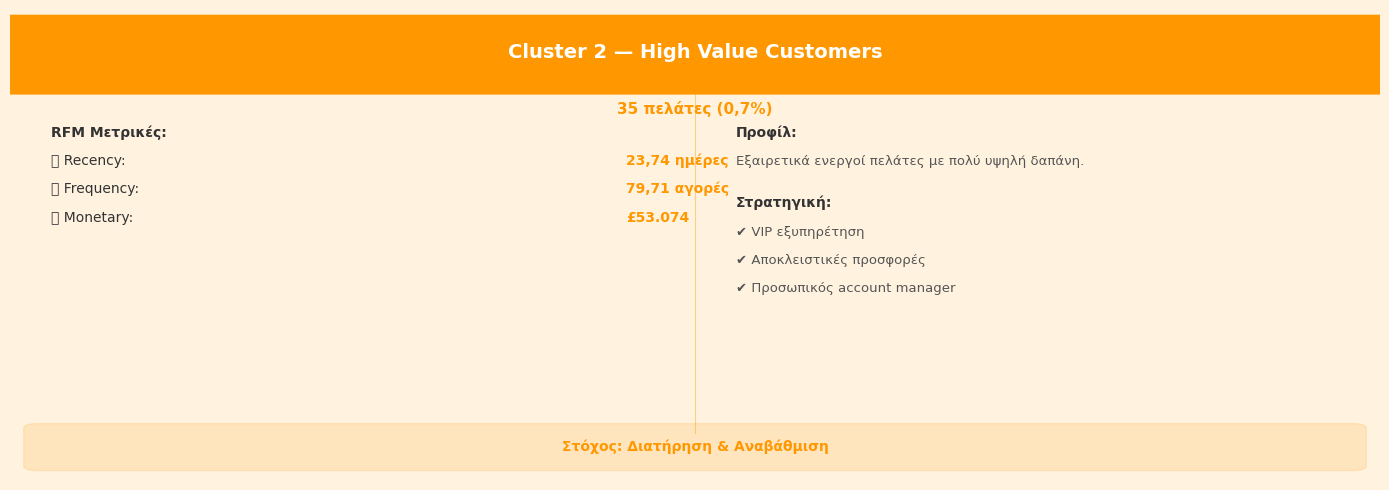

✅ Cluster 2 αποθηκεύτηκε: cluster_2_profile.png


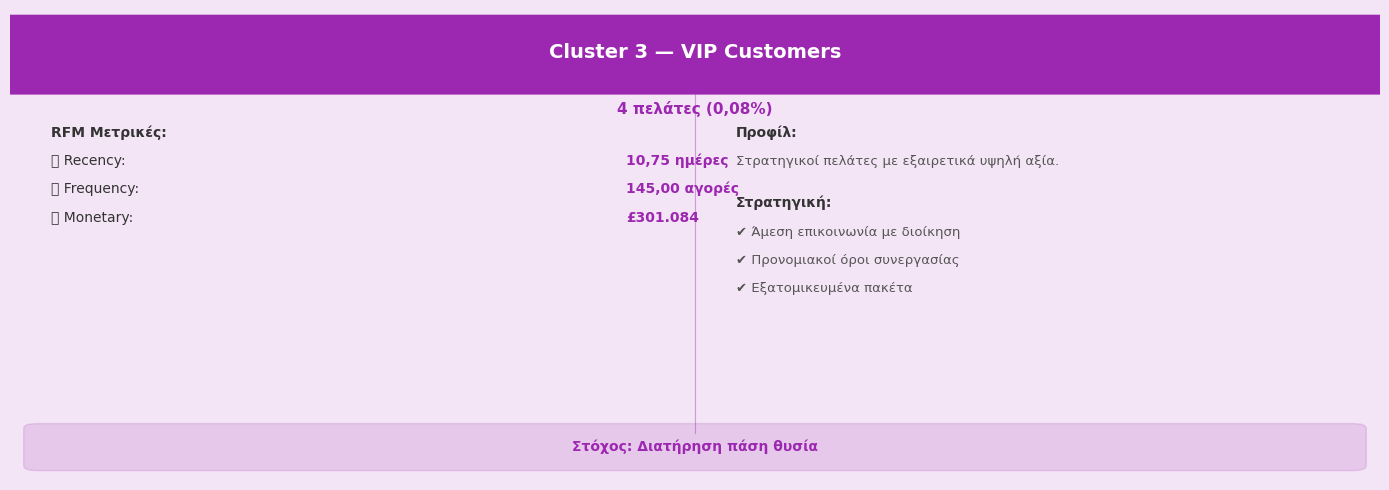

✅ Cluster 3 αποθηκεύτηκε: cluster_3_profile.png


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

✅ Όλα κατέβηκαν!


In [ ]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.patches import FancyBboxPatch

clusters = [
    {
        'title': 'Cluster 0 — Regular Customers',
        'color': '#2196F3',
        'light': '#E3F2FD',
        'count': '2.546 πελάτες (51,6%)',
        'metrics': [
            ('Recency', '58,82 ημέρες', '🟢'),
            ('Frequency', '6,86 αγορές', '🟡'),
            ('Monetary', '£2.859', '🟡'),
        ],
        'profile': 'Ενεργοί πελάτες με τακτικές αγορές και μέτρια δαπάνη.',
        'strategy': [
            '✔ Προγράμματα πιστότητας',
            '✔ Cross-selling προτάσεις',
            '✔ Newsletter με προσφορές',
        ],
        'kpi': 'Στόχος: Αύξηση Frequency & Monetary'
    },
    {
        'title': 'Cluster 1 — Lost Customers',
        'color': '#F44336',
        'light': '#FFEBEE',
        'count': '2.348 πελάτες (47,6%)',
        'metrics': [
            ('Recency', '292,08 ημέρες', '🔴'),
            ('Frequency', '2,14 αγορές', '🔴'),
            ('Monetary', '£776', '🔴'),
        ],
        'profile': 'Αδρανείς πελάτες με μεγάλο χρονικό διάστημα από τελευταία αγορά.',
        'strategy': [
            '✔ Καμπάνιες επανενεργοποίησης',
            '✔ Εκπτωτικές προσφορές',
            '✔ Email με "Σας έχουμε χάσει"',
        ],
        'kpi': 'Στόχος: Μείωση Recency'
    },
    {
        'title': 'Cluster 2 — High Value Customers',
        'color': '#FF9800',
        'light': '#FFF3E0',
        'count': '35 πελάτες (0,7%)',
        'metrics': [
            ('Recency', '23,74 ημέρες', '🟢'),
            ('Frequency', '79,71 αγορές', '🟢'),
            ('Monetary', '£53.074', '🟢'),
        ],
        'profile': 'Εξαιρετικά ενεργοί πελάτες με πολύ υψηλή δαπάνη.',
        'strategy': [
            '✔ VIP εξυπηρέτηση',
            '✔ Αποκλειστικές προσφορές',
            '✔ Προσωπικός account manager',
        ],
        'kpi': 'Στόχος: Διατήρηση & Αναβάθμιση'
    },
    {
        'title': 'Cluster 3 — VIP Customers',
        'color': '#9C27B0',
        'light': '#F3E5F5',
        'count': '4 πελάτες (0,08%)',
        'metrics': [
            ('Recency', '10,75 ημέρες', '🟢'),
            ('Frequency', '145,00 αγορές', '🟢'),
            ('Monetary', '£301.084', '🟢'),
        ],
        'profile': 'Στρατηγικοί πελάτες με εξαιρετικά υψηλή αξία.',
        'strategy': [
            '✔ Άμεση επικοινωνία με διοίκηση',
            '✔ Προνομιακοί όροι συνεργασίας',
            '✔ Εξατομικευμένα πακέτα',
        ],
        'kpi': 'Στόχος: Διατήρηση πάση θυσία'
    },
]

for i, cluster in enumerate(clusters):
    fig, ax = plt.subplots(figsize=(14, 5))
    fig.patch.set_facecolor(cluster['light'])
    ax.set_facecolor(cluster['light'])
    ax.set_xlim(0, 10)
    ax.set_ylim(0, 10)
    ax.axis('off')

    # Τίτλος
    ax.add_patch(FancyBboxPatch((0, 8.3), 10, 1.5,
                                boxstyle="round,pad=0.1",
                                facecolor=cluster['color'], edgecolor='none'))
    ax.text(5, 9.1, cluster['title'], ha='center', va='center',
            fontsize=14, fontweight='bold', color='white')

    # Πλήθος
    ax.text(5, 7.9, cluster['count'], ha='center', va='center',
            fontsize=11, color=cluster['color'], fontweight='bold')

    # Metrics (αριστερά)
    ax.text(0.3, 7.3, 'RFM Μετρικές:', fontsize=10, fontweight='bold', color='#333333')
    for j, (metric, value, icon) in enumerate(cluster['metrics']):
        ax.text(0.3, 6.7 - j*0.6, f'{icon} {metric}:', fontsize=10, color='#333333')
        ax.text(4.5, 6.7 - j*0.6, value, fontsize=10, color=cluster['color'],
                fontweight='bold')

    # Διαχωριστική κάθετη γραμμή
    ax.axvline(x=5, ymin=0.1, ymax=0.85, color=cluster['color'], linewidth=0.8, alpha=0.4)

    # Προφίλ (δεξιά)
    ax.text(5.3, 7.3, 'Προφίλ:', fontsize=10, fontweight='bold', color='#333333')
    ax.text(5.3, 6.7, cluster['profile'], fontsize=9.5, color='#555555')

    # Στρατηγική (δεξιά)
    ax.text(5.3, 5.8, 'Στρατηγική:', fontsize=10, fontweight='bold', color='#333333')
    for j, action in enumerate(cluster['strategy']):
        ax.text(5.3, 5.2 - j*0.6, action, fontsize=9.5, color='#555555')

    # KPI bar κάτω
    ax.add_patch(FancyBboxPatch((0.2, 0.3), 9.6, 0.8,
                                boxstyle="round,pad=0.1",
                                facecolor=cluster['color'], alpha=0.15,
                                edgecolor=cluster['color']))
    ax.text(5, 0.7, cluster['kpi'], ha='center', va='center',
            fontsize=10, color=cluster['color'], fontweight='bold')

    plt.tight_layout()
    filename = f'cluster_{i}_profile.png'
    plt.savefig(filename, dpi=150, bbox_inches='tight', facecolor=cluster['light'])
    plt.show()
    print(f'✅ Cluster {i} αποθηκεύτηκε: {filename}')

# Κατέβασε όλα
from google.colab import files
for i in range(4):
    files.download(f'cluster_{i}_profile.png')

print('✅ Όλα κατέβηκαν!')

from google.colab import files

# Κατέβασε όλα τα αρχεία
files.download('clv_dataset_ready.csv')
files.download('df_clean.csv')
files.download('model_results.csv')
files.download('diagram_4_1_monthly_revenue.png')
files.download('diagram_4_2_country_revenue.png')
files.download('diagram_4_3_weekly_revenue.png')
files.download('diagram_4_4_seasonality.png')
files.download('rfm_distributions.png')
files.download('elbow_clusters.png')
files.download('clustering_results.png')
files.download('cluster_profiles_dashboard.png')
files.download('cluster_0_profile.png')
files.download('cluster_1_profile.png')
files.download('cluster_2_profile.png')
files.download('cluster_3_profile.png')
files.download('model_comparison.png')
files.download('predicted_vs_actual.png')
files.download('feature_importance.png')
files.download('nn_learning_curve.png')
files.download('shap_bar.png')
files.download('shap_beeswarm.png')
files.download('shap_dependence.png')
files.download('residual_analysis.png')

print('✅ Όλα κατέβηκαν!')

In [ ]:
from google.colab import files

files.download('rfm_distributions.png')
files.download('elbow_clusters.png')
files.download('predicted_vs_actual.png')
files.download('feature_importance.png')
files.download('nn_learning_curve.png')
files.download('shap_beeswarm.png')
files.download('shap_dependence.png')
files.download('residual_analysis.png')
files.download('model_results.csv')

print('✅ Όλα κατέβηκαν!')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

...

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

✅ Όλα κατέβηκαν!
